# Supplementary Figure S11a. Reactome pathways enriched in microglial trans-eProgram 100

Over-representation analysis (ConsensusPathDB) of the genes in microglial Hotspot *trans*-eProgram 100, which colocalizes at the SEC61G locus. Shown are the six Reactome pathways with the smallest nominal p-values (other sources such as BioCarta are excluded, as in the author's code); the x-axis is $-\log_{10}$ of the nominal hypergeometric p-value and point size is the number of program genes in the pathway. The `q_value` column holds the ConsensusPathDB FDR q-value computed over all reported pathways (all six have q < 0.02).

Input: `data/Figure_S11a_program100_reactome.rds`


In [1]:
library(ggplot2)
d <- readRDS("data/Figure_S11a_program100_reactome.rds")
d[, c("pathway", "p_value", "q_value", "overlap_n", "overlap_genes", "pathway_size")]

,pathway,p_value,q_value,overlap_n,overlap_genes,pathway_size
,<chr>,<dbl>,<dbl>,<int>,<chr>,<int>
1,Nephrin family interactions,0.0001831423,0.003388133,2,NCK1;CASK,23
2,RHOV GTPase cycle,0.0004038869,0.004428597,2,NCK1;SH3RF1,34
3,RHO GTPases Activate WASPs and WAVEs,0.0004787672,0.004428597,2,NCK1;WASF2,37
4,VEGFA-VEGFR2 Pathway,0.0029281687,0.017081671,2,NCK1;WASF2,92
5,Signaling by VEGF,0.0034488821,0.017081671,2,NCK1;WASF2,100
6,Cell-Cell communication,0.0052504855,0.017081671,2,NCK1;CASK,124


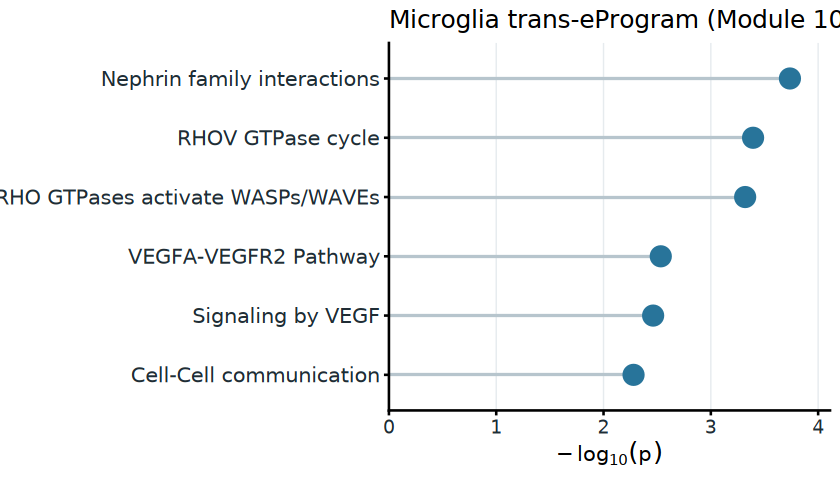

In [2]:
lollipop <- function(d, title, colour = "#28749A", wrap = 45, size_breaks = NULL, xmax = NULL) {
  if (is.null(xmax)) xmax <- max(d$neg_log10_p) * 1.1
  d <- d[order(d$p_value, d$pathway), ]
  d$label <- vapply(d$label, function(x) paste(strwrap(x, width = wrap), collapse = "\n"), character(1))
  d$label <- factor(d$label, levels = rev(d$label))
  ggplot(d, aes(x = neg_log10_p, y = label)) +
    geom_segment(aes(x = 0, xend = neg_log10_p, yend = label), colour = "#B7C5CD", linewidth = 0.7) +
    geom_point(aes(size = overlap_n), colour = colour) +
    scale_size_continuous(name = "Overlap genes", range = c(3, 6),
                          breaks = if (is.null(size_breaks)) sort(unique(d$overlap_n)) else size_breaks,
                          limits = if (is.null(size_breaks)) NULL else range(size_breaks)) +
    scale_x_continuous(limits = c(0, xmax), expand = expansion(mult = c(0, 0))) +
    labs(title = title, x = expression(-log[10](italic(p))), y = NULL) +
    theme_classic(base_size = 12) +
    theme(axis.text.y = element_text(size = 12, colour = "#1F2D35", lineheight = 0.9),
          axis.text.x = element_text(size = 11, colour = "#1F2D35"),
          legend.position = "bottom",
          panel.grid.major.x = element_line(colour = "#E6EBEE", linewidth = 0.3))
}

p <- lollipop(d, "Microglia trans-eProgram (Module 100), Reactome") + theme(legend.position = "none")
options(repr.plot.width = 7, repr.plot.height = 4)
p